In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"  # Force TensorFlow to use CPU

In [2]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import os

In [3]:
# Set the path and other constants
path = "D:\eye-disease-detection\dataset"
os.chdir(path)

In [4]:
BATCH_SIZE = 32
length = 224
width = 149
CHANNELS = 3
EPOCHS = 80

In [5]:
# Load the dataset
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "D:\eye-disease-detection\dataset",
    seed=123,
    shuffle=True,
    image_size=(length, width),
    batch_size=BATCH_SIZE
)

Found 4217 files belonging to 4 classes.


In [6]:
# Get class names
class_names = dataset.class_names
print(class_names)

['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


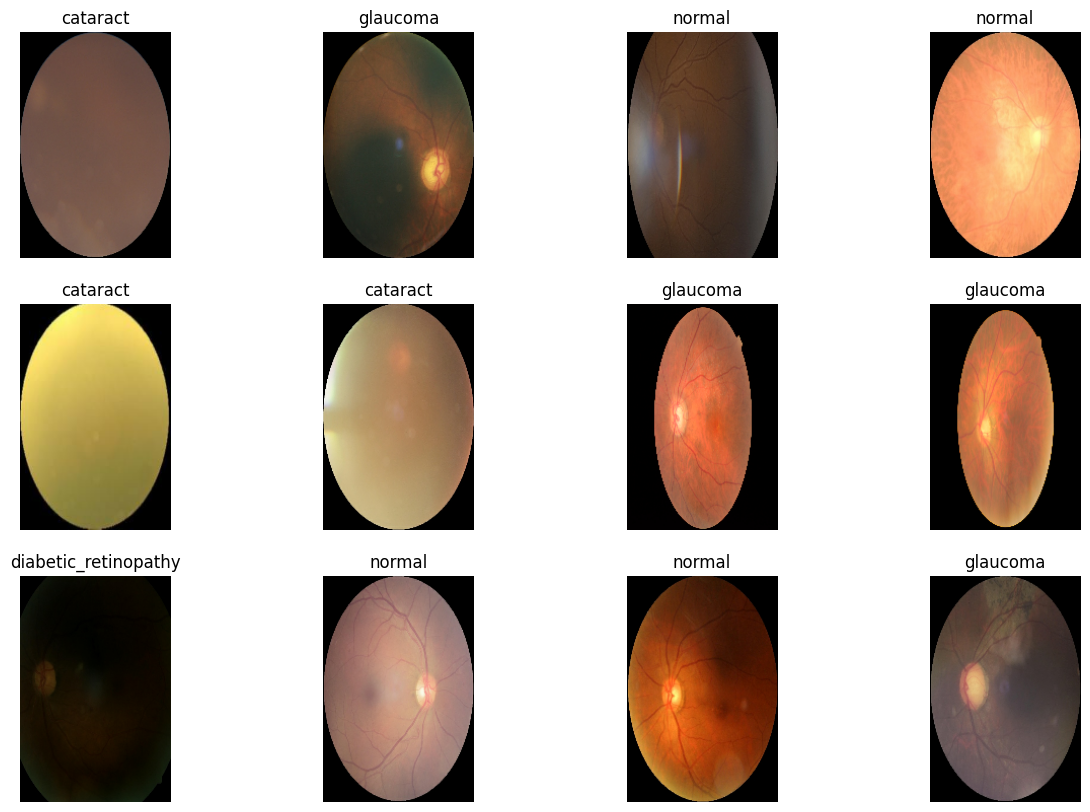

In [7]:
# Visualize some images
plt.figure(figsize=(15, 10))
for image_batch, labels_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])
        plt.axis("off")

In [8]:
len(dataset)

132

In [9]:
# Split the dataset
def get_dataset_partitions_tf(ds, train_split=0.7, val_split=0.10, test_split=0.20, shuffle=True, shuffle_size=100):
    ds_size = len(ds)
    
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    
    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)
    
    train_ds = ds.take(train_size)    
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    
    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [10]:
# Define the resize and rescale layer
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(length, width),
    layers.Rescaling(1./255),
])

In [11]:
# Example usage of the resize_and_rescale layer
for image_batch, labels_batch in train_ds.take(1):
    resized_images = resize_and_rescale(image_batch)
    print(resized_images.shape)

(32, 224, 149, 3)


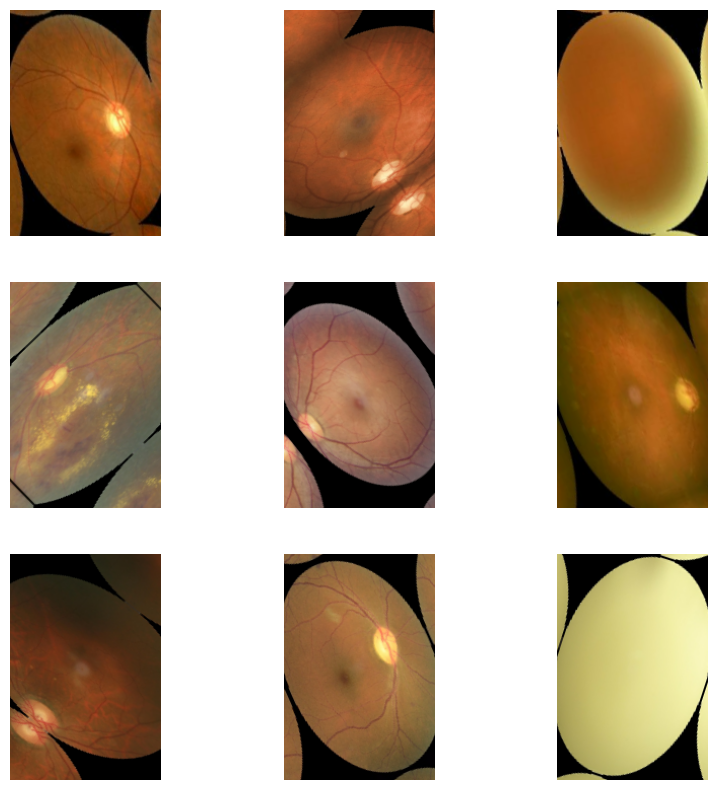

In [12]:
# Define data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

# Example usage of the data_augmentation layer
for image_batch, labels_batch in train_ds.take(1):
    augmented_images = data_augmentation(image_batch)
    plt.figure(figsize=(10, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_images[i].numpy().astype("uint8"))
        plt.axis("off")
    plt.show()

In [13]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y)
).prefetch(buffer_size=tf.data.AUTOTUNE)

In [14]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [15]:
from tensorflow.keras import layers, models

# Define the CNN model
model = tf.keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=[length, width, CHANNELS]),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(120, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(150, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(164, (2, 2), activation='relu'),
    layers.GlobalAveragePooling2D(),  # This layer reduces spatial dimensions to 1
    layers.Dense(4, activation='softmax')  # Output layer with 4 units for 4 classes
])

In [16]:
# Print the model summary
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 222, 147, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 111, 73, 32)       0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 109, 71, 64)       18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 54, 35, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 52, 33, 64)        36928     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 26, 16, 64)       

In [17]:
for i in range(len(model.layers)):
    
# check for convolutional layer
    if 'conv' not in model.layers[i].name:
        continue
# get filter weights
    filters, biases = model.layers[i].get_weights()
    print("layer number",i,model.layers[i].name, filters.shape)

layer number 0 conv2d (3, 3, 3, 32)
layer number 2 conv2d_1 (3, 3, 32, 64)
layer number 4 conv2d_2 (3, 3, 64, 64)
layer number 6 conv2d_3 (3, 3, 64, 120)
layer number 8 conv2d_4 (3, 3, 120, 150)
layer number 10 conv2d_5 (2, 2, 150, 164)


In [18]:
# Retrieve weights from the second convolutional layer
filters, biases = model.layers[2].get_weights()

In [19]:
# Normalize filter values to 0-1 for visualization
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

In [20]:
from keras.models import Model
#from keras.applications.vgg16 import preprocess_input
from keras.preprocessing.image import load_img
from keras.preprocessing.image import img_to_array
from numpy import expand_dims

In [21]:
model = Model(inputs=model.inputs , outputs=model.layers[2].output)

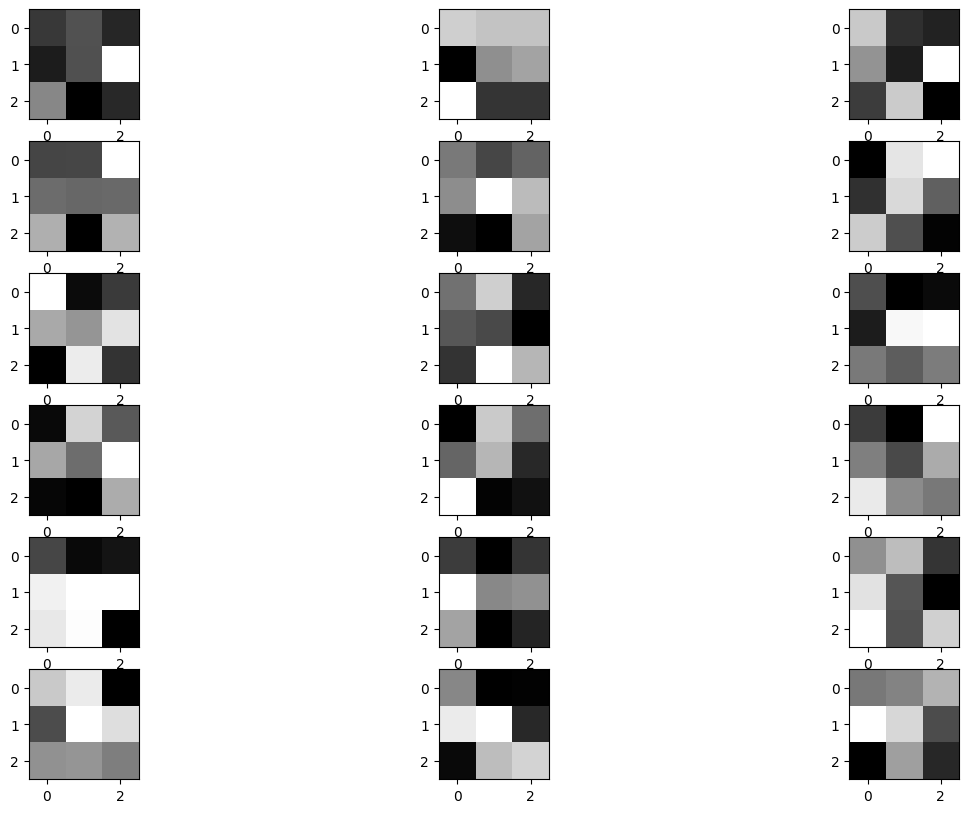

In [22]:
# Visualize the filters
n_filters = 6
ix = 1
plt.figure(figsize=(15, 10))
for i in range(n_filters):
    # Get the filters
    f = filters[:, :, :, i]
    for j in range(3):  # Loop through the 3 channels (RGB)
        plt.subplot(n_filters, 3, ix)
        plt.imshow(f[:, :, j], cmap='gray')
        ix += 1

plt.show()

In [23]:
# redefine model to output right after the first hidden layer
model = Model(inputs=model.inputs, outputs=model.layers[2].output)

In [24]:
# Load and preprocess an image
image = tf.keras.utils.load_img(r'D:\eye-disease-detection\dataset\normal\1034_right.jpg', target_size=(length, width))
image = tf.keras.utils.img_to_array(image)  # Convert the image to an array
image = np.expand_dims(image, axis=0)  # Expand dimensions to represent a single 'sample'
image = resize_and_rescale(image)  # Preprocess the image using the resize_and_rescale layer

# Verify the shape of the preprocessed image
print("Preprocessed image shape:", image.shape)  # Should be (1, 224, 149, 3)

Preprocessed image shape: (1, 224, 149, 3)


1/1 [==============================] - 0s 200ms/step


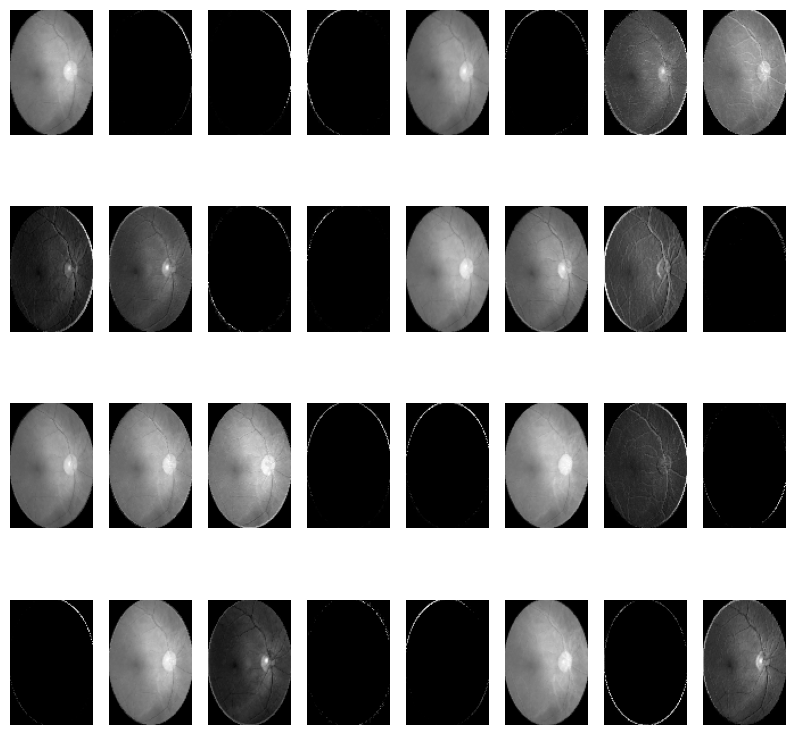

In [25]:
import matplotlib.pyplot as plt

# Calculate feature maps
features = model.predict(image)

# Plot feature maps
fig = plt.figure(figsize=(10, 20))
for i in range(1, features.shape[3] + 1):
    plt.subplot(8, 8, i)
    plt.imshow(features[0, :, :, i - 1], cmap='gray')
    plt.axis('off')  # Hide axes for better visualization

plt.show()

1/1 [==============================] - 0s 25ms/step


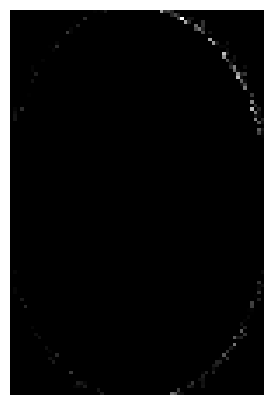

In [26]:
import matplotlib.pyplot as plt

# Calculate feature maps
features = model.predict(image)

# Plot feature maps
fig = plt.figure(figsize=(5, 5))
plt.imshow(features[0, :, :, 27], cmap='gray')  # Replace `i-27` with a valid index (e.g., 27)
plt.axis('off')  # Hide axes for better visualization
plt.show()

In [27]:
# Compile the model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),  # Use SparseCategoricalCrossentropy for integer labels
    metrics=['accuracy']
)

Found 4217 files belonging to 4 classes.
Using 3374 files for training.
Found 4217 files belonging to 4 classes.
Using 843 files for validation.
Found 4217 files belonging to 4 classes.
Visualizing images for cataract...


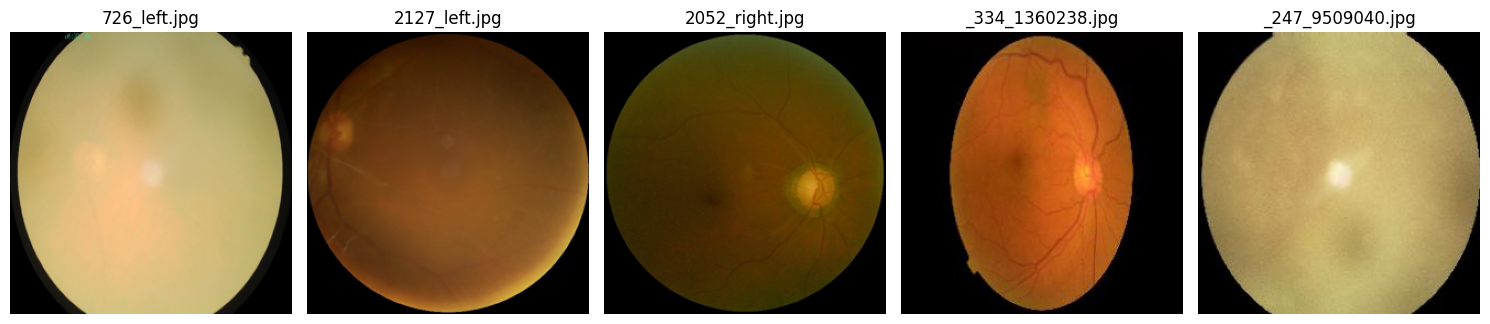

Visualizing images for diabetic_retinopathy...


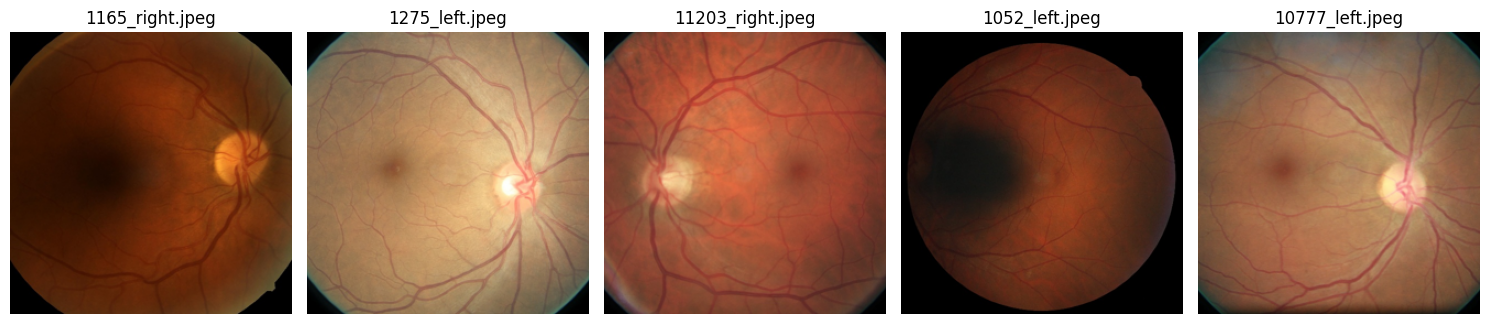

Visualizing images for glaucoma...


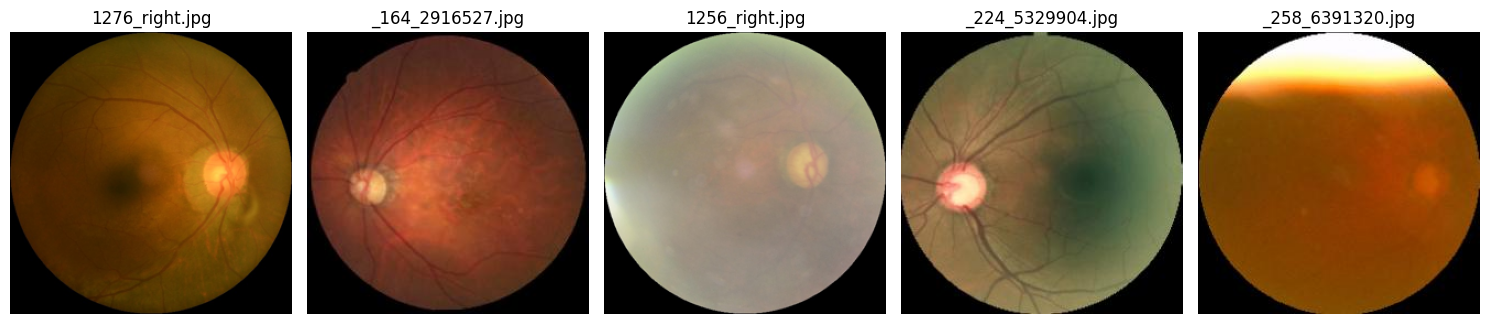

Visualizing images for normal...


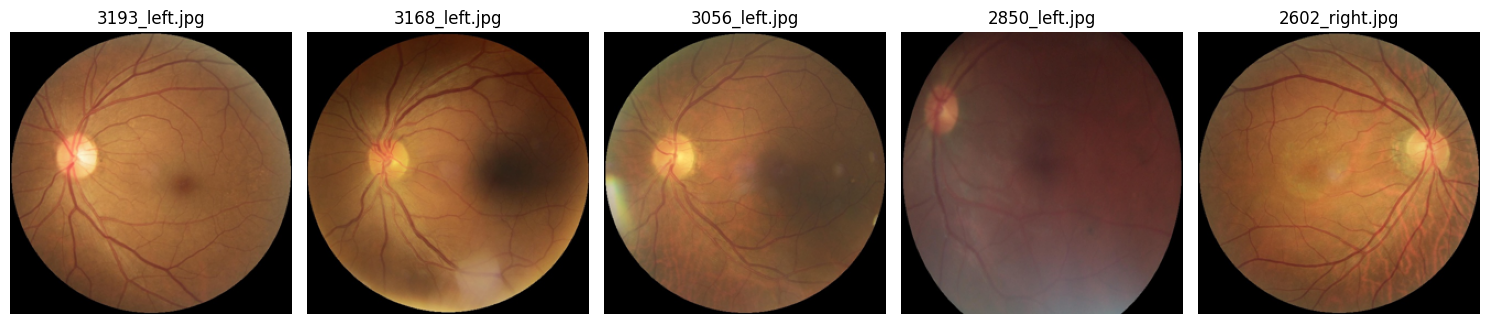

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 254, 254, 32)      896       
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 127, 127, 32)      0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 62, 62, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (None, 60, 60, 128)       73856     
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 30, 30, 128)      

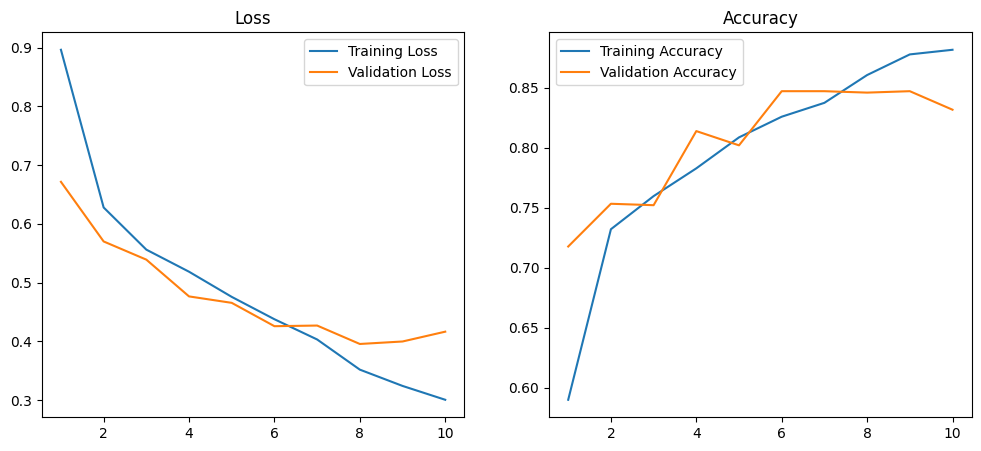

132/132 [==============================] - 53s 398ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.83      0.87      1038
           1       1.00      1.00      1.00      1098
           2       0.84      0.84      0.84      1007
           3       0.84      0.92      0.87      1074

    accuracy                           0.90      4217
   macro avg       0.90      0.90      0.90      4217
weighted avg       0.90      0.90      0.90      4217



In [29]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from PIL import Image

# Rescale function
def preprocess_image(image, label):
    image = tf.image.resize(image, (256, 256)) / 255.0
    return image, label

# Load and preprocess datasets
def load_dataset(directory, subset, validation_split=0.2, batch_size=32):
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory=directory,
        image_size=(256, 256),
        batch_size=batch_size,
        validation_split=validation_split,
        subset=subset,
        seed=42,
        label_mode='categorical'
    )
    return dataset.map(preprocess_image)

# Paths to the dataset
data_path = 'D:\eye-disease-detection\dataset'

train_ds = load_dataset(data_path, subset="training")
val_ds = load_dataset(data_path, subset="validation")
test_ds = tf.keras.utils.image_dataset_from_directory(
    directory=data_path,
    image_size=(256, 256),
    batch_size=32,
    label_mode='categorical',
    shuffle=False
).map(preprocess_image)

# Visualize random images
def visualize_images(path, num_images=5):
    image_files = [os.path.join(path, f) for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]
    selected_images = random.sample(image_files, min(num_images, len(image_files)))

    plt.figure(figsize=(15, 5))
    for i, image_path in enumerate(selected_images):
        img = Image.open(image_path).resize((256, 256))
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(os.path.basename(image_path))
    plt.tight_layout()
    plt.show()

# Visualize examples from each class
for disease_class in ["cataract", "diabetic_retinopathy", "glaucoma", "normal"]:
    print(f"Visualizing images for {disease_class}...")
    visualize_images(os.path.join(data_path, disease_class))

# Define CNN model
def create_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(256, 256, 3)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(4, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = create_model()
model.summary()

# Train the model
early_stopping = EarlyStopping(patience=5, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Plot training results
def plot_training_results(history):
    epochs = range(1, len(history.history['loss']) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history.history['loss'], label='Training Loss')
    plt.plot(epochs, history.history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history.history['accuracy'], label='Training Accuracy')
    plt.plot(epochs, history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.legend()

    plt.show()

plot_training_results(history)

# Classification report
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_true, axis=1)

print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes))

In [30]:
# Save the model in HDF5 (.h5) format
model.save('eye_disease_model.h5')
print("Model saved successfully as eye_disease_model.h5")

C:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Model saved successfully as eye_disease_model.h5
